<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/class_activity_presentatio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Satis activity

In [2]:
import pandas as pd
import numpy as np

In [3]:
path = 'https://raw.githubusercontent.com/tec03/Datasets/refs/heads/main/datasets/satis.csv'

In [5]:
df= pd.read_csv(path)
df.head(5)

,Age,Gender,Ocupation,Monthly income,Price,Quality,Quantity,Availability,Taste,Flavours,...,Overal satisfaction,Consistency,Factor,Frowned,reason,Popular,My favorite,Kind,Preference,Recommend
0,33.0,Male,Research,">40, 000",5.0,5.0,5.0,4.0,4.0,5.0,...,4.0,4.0,Taste,No,NaN,Combo_VLM,Chocolate,More than one flavoured,agree,agree
1,39.0,Male,student,"<10,000",3.0,5.0,3.0,4.0,5.0,5.0,...,4.0,4.0,Taste,No,Quantity issues,Combo_VCS,Chocolate,More than one flavoured,neutral,neutral
2,40.0,Female,Teaching,">40, 000",3.0,4.0,4.0,4.0,3.0,4.0,...,4.0,4.0,Taste,No,NaN,Combo_VCS,Caramel,More than one flavoured,disagree,neutral
3,27.0,Male,Student,"<10,000",5.0,5.0,3.0,4.0,5.0,5.0,...,4.0,4.0,Taste,No,NaN,Combo_VCS,Strawbery,More than one flavoured,agree,agree
4,23.0,Female,Tutor,"10,000 - 20,000",5.0,5.0,4.0,4.0,5.0,5.0,...,5.0,5.0,Quality,No,NaN,Combo_VCS,Vanila,single flavoured,agree,Strongly agree


In [8]:
columns_fav = ['Age','Gender','Price', 'Quality']

In [9]:
ndf = df[columns_fav]
ndf.head()

,Age,Gender,Price,Quality
0,33.0,Male,5.0,5.0
1,39.0,Male,3.0,5.0
2,40.0,Female,3.0,4.0
3,27.0,Male,5.0,5.0
4,23.0,Female,5.0,5.0


In [13]:
def cus_cls(x):
  if 0 <= x <=20:
    return '0-20'
  elif 20 < x <=30:
    return '21-30'
  elif 30 < x <=40:
    return '31-40'
  return '>=40'

In [14]:
cus_cls(15)

'0-20'

In [15]:
cus_cls(-15)

'>=40'

In [16]:
ndf['AgeGP'] = ndf['Age'].apply(cus_cls)
ndf.head()

/tmp/ipykernel_3168/4196775617.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  ndf['AgeGP'] = ndf['Age'].apply(cus_cls)


,Age,Gender,Price,Quality,AgeGP
0,33.0,Male,5.0,5.0,31-40
1,39.0,Male,3.0,5.0,31-40
2,40.0,Female,3.0,4.0,31-40
3,27.0,Male,5.0,5.0,21-30
4,23.0,Female,5.0,5.0,21-30


## Pivot table

In [27]:
age_gp_count = pd.pivot_table(ndf,
                            index = 'AgeGP',
                            values = 'Price',
                            aggfunc= 'count')
age_gp_count

,Price
AgeGP,
0-20,11
21-30,30
31-40,7
>=40,2


In [29]:
new_names = {'Price': 'count_AgeGP'}
age_gp_count.rename(columns = new_names,
                    inplace = True)
age_gp_count


,count_AgeGP
AgeGP,
0-20,11
21-30,30
31-40,7
>=40,2


In [30]:
age_gp_count = age_gp_count.reset_index()
age_gp_count

,AgeGP,count_AgeGP
0,0-20,11
1,21-30,30
2,31-40,7
3,>=40,2


## Graphing

In [31]:
explode_list = [0.01, 0.03, 0.03, 0.02]
colors_list = ['gold', 'yellowgreen', 'coral', 'skyblue']

In [34]:
import matplotlib.pyplot as plt

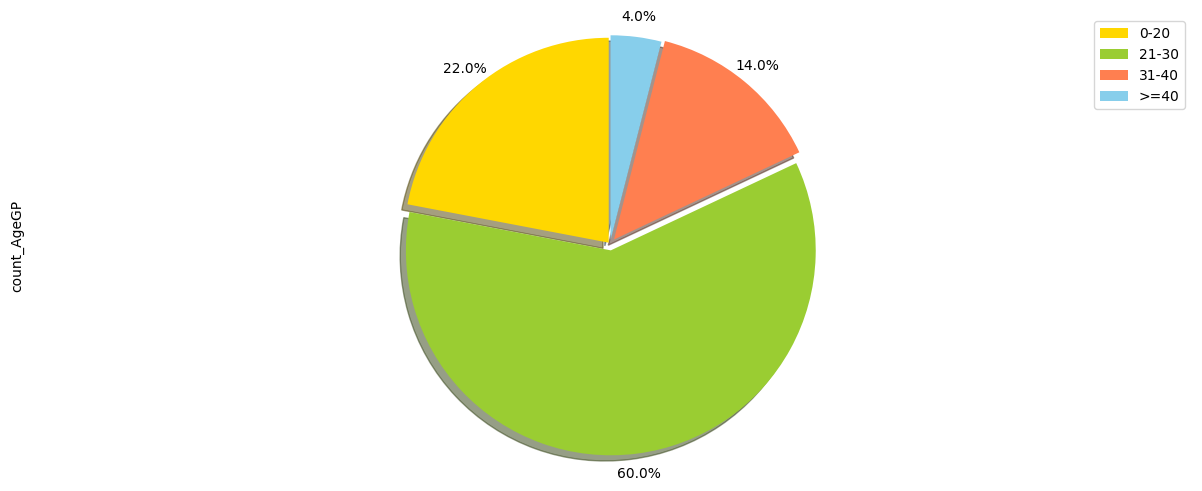

In [36]:

age_gp_count['count_AgeGP'].plot(kind='pie',
                           figsize=(15, 6),
                           autopct='%1.1f%%',
                           startangle=90,
                           shadow=True,
                           labels=None,                  # turn off labels on pie chart
                           pctdistance=1.1,              # the ratio between the pie center and start of text label
                           explode=explode_list,         # 'explode' lowest 3 continents
                           colors=colors_list,
                         )

plt.axis('equal')
plt.legend(labels=age_gp_count.AgeGP,
           bbox_to_anchor=(1.0,1.0))